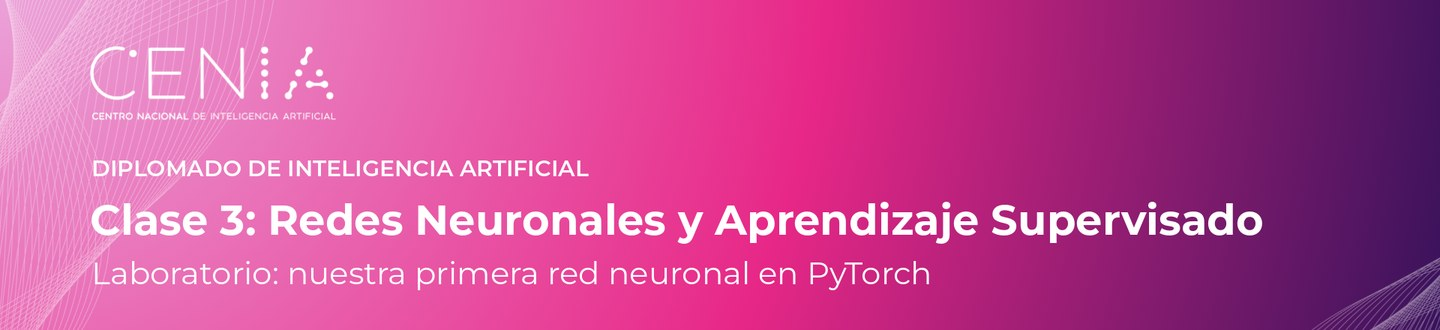

En la clase vimos qué es una red neuronal, cómo viaja la información por ella (el **forward pass**) y cuáles son los componentes del **aprendizaje supervisado**. En este laboratorio vamos a ver que todo eso **ocurre de verdad** en código.

**¿Qué vamos a hacer?**

1. Revisar en PyTorch lo que calculamos a mano en la clase.
2. Conocer un dataset de imágenes: **MNIST** (dígitos escritos a mano).
3. Armar un **MLP**.
4. Entrenarlo con el **ciclo de entrenamiento** completo.
5. Mirar por dentro qué aprendió la red (¡y dibujar nuestros propios números!).
6. Hacer algunos experimentos rápidos.

**Antes de empezar:**

* Activen la GPU: menú **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU** (por ejemplo, T4).
* Ejecuten las celdas **en orden** con `Shift + Enter`.
* No hay actividades evaluadas: la idea es ejecutar, mirar y jugar. Cambien números y vean qué pasa.

> **Ojo:** en este laboratorio vamos a usar varias piezas (la función de pérdida, el optimizador, *backpropagation*) sin explicarlas en detalle. Por ahora nos basta con entender **su rol**. Cada una la verán en detalle en las próximas clases.

## 0. Preparación

Importamos las librerías y fijamos una **semilla** para que los resultados sean reproducibles (los números "al azar" salen siempre iguales).

In [ ]:
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from IPython.display import clear_output, display

torch.manual_seed(0)
np.random.seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Vamos a usar:", device)
if device == "cpu":
    print("Ojo: no hay GPU activa. Todo funciona igual, pero más lento.")

In [ ]:
# @title Colores y funciones para graficar (pueden ignorar esta celda) { display-mode: "form" }
from matplotlib.colors import LinearSegmentedColormap

ROSA, MORADO, AZUL, GRIS = "#E62A85", "#454077", "#2B2B62", "#888888"
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": AZUL,
    "axes.titlecolor": AZUL,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
cmap_rosa = LinearSegmentedColormap.from_list("rosa", ["white", ROSA])
cmap_pesos = LinearSegmentedColormap.from_list("pesos", [MORADO, "white", ROSA])


def mostrar_imagenes(imagenes, titulos=None, colores=None, columnas=8, tamano=1.4):
    # Muestra una grilla de imágenes en escala de grises
    n = len(imagenes)
    filas = int(np.ceil(n / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(columnas * tamano, filas * tamano * 1.15))
    for i, ax in enumerate(np.array(axes).reshape(-1)):
        ax.axis("off")
        if i < n:
            ax.imshow(imagenes[i], cmap="gray_r")
            if titulos is not None:
                ax.set_title(titulos[i], fontsize=10,
                             color=colores[i] if colores is not None else AZUL)
    plt.tight_layout()
    plt.show()


def graficar_confusion(y_real, y_pred, clases, tamano=6.5):
    # Matriz de confusión: filas = respuesta correcta, columnas = predicción
    n = len(clases)
    matriz = torch.bincount(y_real * n + y_pred, minlength=n * n).reshape(n, n)
    fig, ax = plt.subplots(figsize=(tamano, tamano))
    ax.imshow(matriz, cmap=cmap_rosa)
    for i in range(n):
        for j in range(n):
            valor = matriz[i, j].item()
            ax.text(j, i, valor, ha="center", va="center", fontsize=8,
                    color="white" if valor > matriz.max() / 2 else AZUL)
    ax.set_xticks(range(n))
    ax.set_xticklabels(clases, rotation=0 if len(clases[0]) < 3 else 45, ha="center" if len(clases[0]) < 3 else "right")
    ax.set_yticks(range(n))
    ax.set_yticklabels(clases)
    ax.set_xlabel("predicción")
    ax.set_ylabel("respuesta correcta")
    plt.show()


def barras_probabilidad(ax, probs, clases, correcta=None):
    # Barras con la probabilidad que la red le asigna a cada clase
    colores = [GRIS] * len(clases)
    colores[int(np.argmax(probs))] = ROSA
    ax.bar(range(len(clases)), probs, color=colores)
    ax.set_xticks(range(len(clases)))
    ax.set_xticklabels(clases, fontsize=8, rotation=0 if len(clases[0]) < 3 else 45)
    ax.set_ylim(0, 1)
    if correcta is not None:
        ax.get_xticklabels()[correcta].set_color(MORADO)
        ax.get_xticklabels()[correcta].set_fontweight("bold")

## 1. Lo que vimos en clases, ahora en PyTorch

### 1.1 Una neurona

En la clase calculamos a mano esta neurona:

* Entradas: $x = (0.1,\ -0.3,\ 1.4)$
* Pesos: $w = (-0.7,\ -1.4,\ 0.6)$
* Sesgo: $b = 0.1$
* Activación: sigmoide, $\sigma$

y llegamos a $\sigma(1.29) = 0.78$. Hagamos lo mismo en PyTorch.

In [ ]:
x = torch.tensor([0.1, -0.3, 1.4])
w = torch.tensor([-0.7, -1.4, 0.6])
b = torch.tensor(0.1)

productos = w * x
print("Paso 1, multiplicamos cada entrada por su peso:", productos)

z = productos.sum() + b
print("Paso 2, sumamos todo, más el sesgo:            ", z)

y = torch.sigmoid(z)
print("Paso 3, aplicamos la activación (sigmoide):    ", y)

¡Lo mismo que a mano! 🎉

### 1.2 Juguemos con una neurona

La entrada es la misma de la clase, $x = (0.1,\ -0.3,\ 1.4)$. Muevan los pesos, el sesgo y la función de activación, y miren cómo cambia la salida:

* **A la izquierda**, la neurona. Cada flecha muestra su peso: <b>más gruesa</b> mientras más grande el peso, rosada si es positivo y morada si es negativo.
* **A la derecha**, la función de activación. El punto rosado muestra dónde cae la suma ponderada $z$.

In [ ]:
import ipywidgets as widgets
from matplotlib.patches import Circle

# Entrada fija de la clase. Usamos un nombre propio para que ninguna otra celda la cambie.
X_NEURONA = torch.tensor([0.1, -0.3, 1.4])
activaciones = {"sigmoide": torch.sigmoid, "ReLU": torch.relu, "ninguna": lambda t: t}


def dibujar_neurona(ax, x, w, b, z, y, activacion):
    entradas = [(0, 1.1), (0, 0), (0, -1.1)]
    centro, salida = (2.6, 0), (4.4, 0)
    for (px, py), xi, wi in zip(entradas, x, w):
        color = ROSA if wi >= 0 else MORADO
        inicio, fin = (px + 0.3, py), (centro[0] - 0.5, centro[1] + py * 0.25)
        ax.annotate("", xy=fin, xytext=inicio,
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=0.8 + 1.5 * abs(wi)))
        t = 0.4  # la etiqueta va a un 40% del camino, un poco por arriba de la flecha
        ax.text(inicio[0] + t * (fin[0] - inicio[0]), inicio[1] + t * (fin[1] - inicio[1]) + 0.3,
                f"w = {wi:.1f}", color=color, fontsize=10, ha="center", fontweight="bold")
        ax.add_patch(Circle((px, py), 0.3, facecolor="#E4E2F0", edgecolor=MORADO))
        ax.text(px, py, f"{xi:.1f}", ha="center", va="center", fontsize=10, color=AZUL)
    ax.add_patch(Circle(centro, 0.5, facecolor="#FBE3EF", edgecolor=ROSA, lw=1.5))
    ax.text(centro[0], centro[1] + 0.12, "Σ", ha="center", va="center", fontsize=16, color=AZUL)
    ax.text(centro[0], centro[1] - 0.22, activacion, ha="center", va="center", fontsize=8, color=AZUL)
    ax.annotate("", xy=(centro[0], 0.5), xytext=(centro[0], 1.25),
                arrowprops=dict(arrowstyle="-|>", color=GRIS))
    ax.text(centro[0], 1.4, f"b = {b:.1f}", ha="center", fontsize=10, color=AZUL)
    ax.text(centro[0], -0.85, f"z = {z:.2f}", ha="center", fontsize=10, color=AZUL)
    ax.annotate("", xy=(salida[0] - 0.38, 0), xytext=(centro[0] + 0.5, 0),
                arrowprops=dict(arrowstyle="-|>", color=AZUL))
    ax.add_patch(Circle(salida, 0.38, facecolor=ROSA, edgecolor=ROSA))
    ax.text(*salida, f"{y:.2f}", ha="center", va="center", fontsize=10, color="white",
            fontweight="bold")
    ax.text(0, -1.65, "entradas x", ha="center", fontsize=9, color=GRIS)
    ax.text(salida[0], -0.65, "salida y", ha="center", fontsize=9, color=GRIS)
    ax.set_xlim(-0.6, 5.0)
    ax.set_ylim(-1.9, 1.7)
    ax.set_aspect("equal")
    ax.axis("off")


def neurona(w1=-0.7, w2=-1.4, w3=0.6, b=0.1, activacion="sigmoide"):
    w = torch.tensor([w1, w2, w3])
    g = activaciones[activacion]
    z = (w * X_NEURONA).sum() + b
    y = g(z)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
    dibujar_neurona(ax1, X_NEURONA.tolist(), w.tolist(), b, z.item(), y.item(), activacion)

    zs = torch.linspace(-6, 6, 200)
    ax2.plot(zs, g(zs), color=MORADO, lw=2)
    ax2.scatter([z.item()], [y.item()], color=ROSA, s=120, zorder=3)
    ax2.axhline(0, color=GRIS, lw=0.5)
    ax2.axvline(0, color=GRIS, lw=0.5)
    ax2.set_xlabel("suma ponderada z")
    ax2.set_ylabel(f"{activacion}(z)")
    ax2.set_title(f"z = {z.item():.2f}    →    salida y = {y.item():.2f}")
    plt.tight_layout()
    plt.show()


widgets.interact(neurona,
                 w1=(-3.0, 3.0, 0.1), w2=(-3.0, 3.0, 0.1), w3=(-3.0, 3.0, 0.1),
                 b=(-3.0, 3.0, 0.1), activacion=list(activaciones));

### 1.3 La red de la clase

Ahora armemos la red de la clase: **3 entradas → 6 neuronas → 4 neuronas → 1 salida**, con sigmoide entre las capas.

En PyTorch, una red se escribe como una **clase** que hereda de `nn.Module` y que tiene dos partes:

| Parte | ¿Qué hace? | ¿Cuándo se ejecuta? |
|---|---|---|
| `__init__` | **Crea las capas**. Al crearlas, PyTorch crea sus parámetros (pesos y sesgos) al azar. | Una sola vez, cuando creamos la red: `red = RedClase()` |
| `forward` | Define el **forward pass**: cómo viaja la información desde la entrada hasta la salida. | Cada vez que le pasamos datos: `red(x)` |

In [ ]:
class RedClase(nn.Module):

    def __init__(self):
        super().__init__()   # línea obligatoria: prepara la clase como una red de PyTorch

        # Creamos las capas (y con ellas, los parámetros)
        self.capa1 = nn.Linear(3, 6)     # Lineal 1: 3 -> 6
        self.capa2 = nn.Linear(6, 4)     # Lineal 2: 6 -> 4
        self.salida = nn.Linear(4, 1)    # Lineal 3: 4 -> 1
        self.activacion = nn.Sigmoid()   # sigma

    def forward(self, x):
        # El forward pass: cómo viaja la información
        h1 = self.activacion(self.capa1(x))    # capa oculta 1
        h2 = self.activacion(self.capa2(h1))   # capa oculta 2
        y_hat = self.salida(h2)                # salida
        return y_hat


red = RedClase()   # se ejecuta __init__
red

Comparen con la diapositiva "Misma red: otra visualización" de la clase: `__init__` crea los bloques (Lineal 1, Lineal 2, Lineal 3 y $\sigma$) y `forward` los conecta en orden.

PyTorch crea los pesos **al azar**. Vamos a reemplazarlos por los mismos pesos que usamos en la clase, para comparar los resultados.

In [ ]:
W1 = torch.tensor([[-0.7, -1.4,  0.6],
                   [-1.7,  0.1, -0.5],
                   [-1.8,  0.0, -1.9],
                   [-0.3, -1.7, -1.6],
                   [-0.3,  1.3, -1.5],
                   [-1.1,  0.5,  1.8]])
b1 = torch.tensor([0.1, -0.1, 0.5, -0.5, 0.4, -0.2])
W2 = torch.tensor([[-1.4, -1.5, -0.8,  1.3, -1.3,  0.3],
                   [ 0.6, -0.5,  0.2, -1.7, -1.8, -1.2],
                   [ 0.7, -0.3, -0.7,  0.3, -0.2, -0.8],
                   [ 1.2,  0.8, -1.0,  0.3,  0.1,  1.5]])
b2 = torch.tensor([0.2, -0.2, 0.5, -0.4])
W3 = torch.tensor([[1.2, -0.9, 1.4, 1.6]])
b3 = torch.tensor([0.3])

with torch.no_grad():  # sólo estamos copiando valores, no entrenando
    red.capa1.weight.copy_(W1);  red.capa1.bias.copy_(b1)
    red.capa2.weight.copy_(W2);  red.capa2.bias.copy_(b2)
    red.salida.weight.copy_(W3); red.salida.bias.copy_(b3)

x = torch.tensor([0.1, -0.3, 1.4])
y_hat = red(x)   # se ejecuta forward

# Para "mirar" a mitad de camino, repetimos los pasos del forward uno por uno
h1 = red.activacion(red.capa1(x))
h2 = red.activacion(red.capa2(h1))

print("Capa oculta 1, h1:", h1.detach().numpy().round(2))
print("Capa oculta 2, h2:", h2.detach().numpy().round(2))
print("Salida, y_hat:    ", y_hat.detach().numpy().round(2))

Son exactamente los valores de la diapositiva "Así viaja la información" de la clase: la capa 1 da $(0.78,\ 0.27,\ 0.09,\ 0.09,\ 0.11,\ 0.89)$ y la salida es $\hat y = 2.58$.

Fíjense en tres cosas:

* **Nunca llamamos a `forward` directamente**: escribimos `red(x)` y PyTorch se encarga de llamarlo.
* Para "mirar" el forward pass a mitad de camino, repetimos sus pasos uno por uno.
* La primera neurona de la capa 1 vale **0.78**: es la neurona que calculamos a mano.

### 1.4 Cada fila de $W$ es una neurona

In [ ]:
print("Forma de W1:", tuple(red.capa1.weight.shape), "-> 6 neuronas, cada una con 3 pesos")
print("Fila 1 de W1:", red.capa1.weight[0].detach().numpy(), "-> ¡los pesos de nuestra neurona!")

### 1.5 ¿Cuántos parámetros tiene?

En la clase contamos **57** parámetros. Contémoslos con PyTorch:

In [ ]:
for nombre, p in red.named_parameters():
    print(f"{nombre:13s} forma {str(tuple(p.shape)):8s} -> {p.numel():3d} parámetros")
print("Total:", sum(p.numel() for p in red.parameters()))

### 1.6 Sin activaciones, la red colapsa

En la clase vimos que si sacamos las funciones de activación, varias capas lineales seguidas equivalen a **una sola capa lineal**:

$$W_3\big(W_2\,(W_1\, x)\big) = \underbrace{(W_3 W_2 W_1)}_{W}\, x = W x$$

Comprobémoslo con números. Armamos la misma red, pero **sin activaciones** en el `forward` (y sin sesgos, para que se vea más simple):

In [ ]:
class RedSinActivacion(nn.Module):

    def __init__(self):
        super().__init__()
        self.capa1 = nn.Linear(3, 6, bias=False)
        self.capa2 = nn.Linear(6, 4, bias=False)
        self.salida = nn.Linear(4, 1, bias=False)

    def forward(self, x):
        return self.salida(self.capa2(self.capa1(x)))   # ¡sin funciones de activación!


sin_activacion = RedSinActivacion()

# Juntamos las tres matrices en una sola
W = sin_activacion.salida.weight @ sin_activacion.capa2.weight @ sin_activacion.capa1.weight
print("Forma de la matriz W:", tuple(W.shape), "-> ¡una sola capa lineal de 3 -> 1!")

ejemplos = torch.randn(5, 3)  # 5 ejemplos al azar
print("Red de 3 capas:", sin_activacion(ejemplos).detach().numpy().ravel().round(4))
print("Una sola capa: ", (ejemplos @ W.T).detach().numpy().ravel().round(4))

Dan exactamente lo mismo. Por eso las funciones de activación tienen que ser **no lineales**: sin ellas, agregar capas no sirve de nada.

## 2. Conociendo los datos: MNIST

Ahora vamos a un problema de verdad. **MNIST** es un dataset de 70.000 imágenes de dígitos escritos a mano, del 0 al 9. Cada imagen tiene su **etiqueta**: el dígito que es.

Es un problema de **aprendizaje supervisado** de **clasificación**:

* Entrada $x$: una imagen de 28 × 28 pixeles.
* Salida $y$: el dígito (10 clases posibles).

### 2.1 Descargar los datos

In [ ]:
from torchvision import datasets

entrenamiento_mnist = datasets.MNIST(root="datos", train=True, download=True)
test_mnist = datasets.MNIST(root="datos", train=False, download=True)

# Pasamos las imágenes a números entre 0 y 1 (0 = blanco, 1 = trazo)
X_todo = entrenamiento_mnist.data.float() / 255
y_todo = entrenamiento_mnist.targets
X_test = test_mnist.data.float() / 255
y_test = test_mnist.targets
clases = [str(i) for i in range(10)]

print("Imágenes de entrenamiento:", tuple(X_todo.shape))
print("Imágenes de test:         ", tuple(X_test.shape))

### 2.2 Miremos algunas imágenes con su etiqueta

In [ ]:
indices = torch.randint(len(X_todo), (24,))
mostrar_imagenes(X_todo[indices], titulos=[f"etiqueta: {y_todo[i].item()}" for i in indices])

### 2.3 ¿Cuántos ejemplos hay de cada dígito?

Siempre es bueno revisar si las clases están balanceadas.

In [ ]:
conteo = torch.bincount(y_todo, minlength=10)
plt.figure(figsize=(7, 3))
plt.bar(clases, conteo, color=ROSA)
plt.xlabel("dígito")
plt.ylabel("cantidad de imágenes")
plt.title("Ejemplos por clase en entrenamiento")
plt.show()

Más o menos 6.000 de cada uno: está bien balanceado.

### 2.4 La red sólo ve números

Para nosotros es un dibujo. Para la red, es una **matriz de 28 × 28 números**. Acá está cada pixel con su valor:

In [ ]:
imagen = X_todo[0]
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(imagen, cmap=cmap_rosa)
for i in range(28):
    for j in range(28):
        valor = round(imagen[i, j].item(), 1)
        texto = "0" if valor == 0 else "1" if valor == 1 else f"{valor:.1f}".lstrip("0")
        ax.text(j, i, texto, ha="center", va="center", fontsize=5,
                color="white" if valor > 0.5 else AZUL)
ax.set_title(f"Etiqueta: {y_todo[0].item()}")
ax.axis("off")
plt.show()

Un MLP recibe **vectores**, así que "aplanamos" la imagen: ponemos las 28 filas una al lado de la otra y queda un vector de $28 \times 28 = 784$ números.

In [ ]:
vector = imagen.reshape(-1)  # aplanar
print("Imagen:", tuple(imagen.shape), "->  vector:", tuple(vector.shape))

plt.figure(figsize=(14, 1))
plt.imshow(vector[None, :], cmap=cmap_rosa, aspect="auto")
plt.yticks([])
plt.xlabel("posición en el vector (0 a 783)")
plt.title("La misma imagen, como un vector de 784 números")
plt.show()

### 2.5 El dígito "promedio"

Si promediamos todas las imágenes de cada clase, vemos la forma "típica" de cada dígito. Guarden esta imagen en la cabeza: en la sección 5 la vamos a comparar con lo que aprendió la red.

In [ ]:
promedios = [X_todo[y_todo == c].mean(dim=0) for c in range(10)]
mostrar_imagenes(promedios, titulos=[f"promedio de {c}" for c in clases], columnas=10)

### 2.6 Codificando la respuesta correcta: *one-hot*

Como vimos en la clase, para clasificación la respuesta correcta se escribe como un vector **one-hot**: un **1** en la clase correcta y **0** en el resto. Por eso nuestra red va a tener **10 neuronas de salida**, una por dígito.

In [ ]:
ejemplos = y_todo[:6]
one_hot = F.one_hot(ejemplos, num_classes=10)
print(one_hot)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.imshow(one_hot, cmap=cmap_rosa)
ax.set_xticks(range(10))
ax.set_xlabel("clase")
ax.set_yticks(range(len(ejemplos)))
ax.set_yticklabels([f"etiqueta {e.item()}" for e in ejemplos])
for i in range(len(ejemplos)):
    for j in range(10):
        ax.text(j, i, one_hot[i, j].item(), ha="center", va="center",
                color="white" if one_hot[i, j] else AZUL)
plt.show()

> En la práctica, PyTorch hace esta conversión por dentro: le pasamos directamente la etiqueta (por ejemplo `3`) y la función de pérdida se encarga.

### 2.7 Entrenamiento, validación y test

Separamos los datos en tres partes, como en la clase:

* **Entrenamiento**: para aprender los parámetros.
* **Validación**: para tomar decisiones mientras entrenamos (por ejemplo, cuándo parar).
* **Test**: para evaluar al final, con datos que la red **nunca vio**.

MNIST ya viene con un conjunto de test de 10.000 imágenes. Del resto, separamos 10.000 para validación.

In [ ]:
orden = torch.randperm(len(X_todo))
idx_val, idx_entr = orden[:10_000], orden[10_000:]

X_entr, y_entr = X_todo[idx_entr], y_todo[idx_entr]
X_val, y_val = X_todo[idx_val], y_todo[idx_val]

tamanos = {"Entrenamiento": len(X_entr), "Validación": len(X_val), "Test": len(X_test)}
plt.figure(figsize=(10, 1.2))
inicio = 0
for (nombre, n), color in zip(tamanos.items(), ["#B9B6D3", "#F3A1C9", ROSA]):
    plt.barh(0, n, left=inicio, color=color)
    plt.text(inicio + n / 2, 0, f"{nombre}\n{n:,}".replace(",", "."), ha="center", va="center",
             color=AZUL if color != ROSA else "white", fontsize=10)
    inicio += n
plt.axis("off")
plt.show()

### 2.8 Minibatches: muchos ejemplos a la vez

No le pasamos a la red las imágenes de a una: las agrupamos en **minibatches**. El `DataLoader` se encarga de armarlos (y de desordenar los datos en cada época).

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

TAMANO_BATCH = 64
train_loader = DataLoader(TensorDataset(X_entr, y_entr), batch_size=TAMANO_BATCH, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=1000)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=1000)

imagenes, etiquetas = next(iter(train_loader))
print("Un minibatch de imágenes:", tuple(imagenes.shape), "-> 64 imágenes de 28 x 28")
print("Aplanadas:               ", tuple(imagenes.reshape(64, -1).shape), "-> cada fila es un ejemplo")
print("Sus etiquetas:           ", tuple(etiquetas.shape))

Es lo mismo que vimos en la diapositiva "Muchos ejemplos a la vez": una matriz $X$ donde **cada fila es un ejemplo**. Una sola multiplicación de matrices procesa las 64 imágenes juntas.

## 3. El modelo: un MLP

Nuestro MLP:

* **Entrada**: 784 números (la imagen aplanada).
* **Capa oculta 1**: 128 neuronas + ReLU.
* **Capa oculta 2**: 64 neuronas + ReLU.
* **Salida**: 10 neuronas, una por dígito (¡como el one-hot!).

Lo escribimos igual que la red de la clase (sección 1.3): una clase con `__init__`, que **crea las capas**, y `forward`, que define el **forward pass**. Lo único nuevo es el primer paso del `forward`: aplanar la imagen de 28 × 28 a un vector de 784.

In [ ]:
class MLP(nn.Module):

    def __init__(self):
        super().__init__()   # línea obligatoria: prepara la clase como un modelo de PyTorch

        # Creamos las capas (y con ellas, los parámetros)
        self.aplanar = nn.Flatten()          # 28 x 28 -> 784
        self.capa1 = nn.Linear(784, 128)     # capa oculta 1
        self.capa2 = nn.Linear(128, 64)      # capa oculta 2
        self.salida = nn.Linear(64, 10)      # salida: una neurona por clase
        self.activacion = nn.ReLU()

    def forward(self, x):
        # El forward pass: cómo viaja la información
        x = self.aplanar(x)                  # (batch, 28, 28) -> (batch, 784)
        h1 = self.activacion(self.capa1(x))  # capa oculta 1 + ReLU
        h2 = self.activacion(self.capa2(h1)) # capa oculta 2 + ReLU
        y_hat = self.salida(h2)              # salida: 10 números, uno por dígito
        return y_hat


torch.manual_seed(0)
model = MLP().to(device)   # se ejecuta __init__
model

Igual que antes, `model(x)` ejecuta el `forward`. Probémoslo con un minibatch:

In [ ]:
imagenes, _ = next(iter(train_loader))
y_hat = model(imagenes.to(device))   # se ejecuta forward
print("Entrada:", tuple(imagenes.shape), "-> 64 imágenes de 28 x 28")
print("Salida: ", tuple(y_hat.shape), "     -> 64 ejemplos, 10 números cada uno")

In [ ]:
def miles(n):
    return f"{n:,}".replace(",", ".")


total = 0
for nombre, p in model.named_parameters():
    total += p.numel()
    print(f"{nombre:13s} forma {str(tuple(p.shape)):12s} -> {miles(p.numel()):>7s} parámetros")
print(f"\nTotal: {miles(total)} parámetros")
print("La red de la clase tenía 57. GPT-3 tiene 175.000 millones.")

Los nombres de los parámetros (`capa1.weight`, `capa1.bias`, ...) salen de los nombres que les dimos a las capas en `__init__`.

### 3.1 Antes de entrenar, la red predice cualquier cosa

Los parámetros $\theta$ todavía son **aleatorios**. Veamos qué predice.

La red entrega 10 números, uno por clase. Con `softmax` los convertimos en **probabilidades** que suman 1 (lo verán en detalle más adelante).

In [ ]:
# 8 imágenes fijas de test que vamos a seguir durante todo el laboratorio
torch.manual_seed(1)
muestra_idx = torch.randint(len(X_test), (8,))
muestra_x, muestra_y = X_test[muestra_idx], y_test[muestra_idx]


def mostrar_predicciones(model, x, y, clases):
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(x.to(device)), dim=1).cpu().numpy()
    fig, axes = plt.subplots(2, len(x), figsize=(1.8 * len(x), 3.6),
                             gridspec_kw={"height_ratios": [1.2, 1]})
    for i in range(len(x)):
        pred = int(probs[i].argmax())
        color = "#2E9E5B" if pred == y[i] else ROSA
        axes[0, i].imshow(x[i], cmap="gray_r")
        axes[0, i].set_title(f"predice: {clases[pred]}", color=color, fontsize=10)
        axes[0, i].axis("off")
        barras_probabilidad(axes[1, i], probs[i], clases, correcta=int(y[i]))
        axes[1, i].set_yticks([])
    plt.tight_layout()
    plt.show()


mostrar_predicciones(model, muestra_x, muestra_y, clases)

In [ ]:
def evaluar(model, loader):
    # Devuelve la pérdida promedio y la precisión (accuracy) sobre un conjunto de datos
    model.eval()
    perdida, correctas, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            y_hat = model(x)
            perdida += F.cross_entropy(y_hat, y, reduction="sum").item()
            correctas += (y_hat.argmax(dim=1) == y).sum().item()
            total += len(y)
    return perdida / total, correctas / total


_, precision = evaluar(model, test_loader)
print(f"Precisión antes de entrenar: {precision:.1%}")

Las probabilidades son casi parejas y la precisión anda cerca del **10%**: es lo mismo que adivinar al azar entre 10 dígitos. La red todavía no sabe nada.

¡Toca entrenar!

## 4. El ciclo de entrenamiento

Recordemos los componentes del aprendizaje supervisado y dónde aparecen en el código:

| Componente | En el código |
|---|---|
| **Datos** | `train_loader`, `val_loader`, `test_loader` |
| **Modelo** | `model` (nuestro MLP) |
| **Función de pérdida** | `nn.CrossEntropyLoss()`: mide qué tan mal lo hace la red. Es la que se usa para clasificación |
| **Optimización** | `torch.optim.SGD`: ajusta los parámetros con $w \rightarrow w - \mu\, g$ |

Y el ciclo de entrenamiento es el de la clase:

1. Tomar un grupo de ejemplos (**minibatch**).
2. **Forward pass**: calcular $\hat y$.
3. Calcular la **pérdida** $L(\hat y, y)$.
4. Calcular los **gradientes** (*backpropagation*).
5. **Actualizar** los parámetros: $w \rightarrow w - \mu\, g$.

Y repetir. Cada vuelta es una **iteración**; cuando pasamos por todo el dataset una vez, completamos una **época**.

> **Ojo:** no se preocupen por entender cada línea en detalle. Por ahora lo importante es reconocer los 5 pasos.

In [ ]:
# @title Gráfico del progreso del entrenamiento (pueden ignorar esta celda) { display-mode: "form" }
def graficar_progreso(hist, model, x, y, clases, titulo=""):
    model.eval()
    with torch.no_grad():
        preds = model(x.to(device)).argmax(dim=1).cpu()
    model.train()

    fig = plt.figure(figsize=(14, 5.2))
    grid = fig.add_gridspec(2, len(x), height_ratios=[1.6, 1])

    ax = fig.add_subplot(grid[0, : len(x) // 2])
    ax.plot(hist["iter"], hist["perdida"], color=ROSA, lw=1.5, label="entrenamiento")
    if hist["val_perdida"]:
        ax.plot(hist["val_iter"], hist["val_perdida"], "o-", color=MORADO, label="validación")
    ax.set_xlabel("iteración")
    ax.set_title("Pérdida (mientras más chica, mejor)")
    ax.legend()

    ax = fig.add_subplot(grid[0, len(x) // 2:])
    if hist["val_precision"]:
        ax.plot(range(1, len(hist["val_precision"]) + 1), hist["val_precision"], "o-", color=MORADO)
        ax.set_xticks(range(1, len(hist["val_precision"]) + 1))
    ax.set_ylim(0, 1)
    ax.set_xlabel("época")
    ax.set_title("Precisión en validación")

    for i in range(len(x)):
        ax = fig.add_subplot(grid[1, i])
        ax.imshow(x[i], cmap="gray_r")
        ok = preds[i] == y[i]
        ax.set_title(f"predice: {clases[preds[i]]}", color="#2E9E5B" if ok else ROSA, fontsize=10)
        ax.axis("off")
    fig.suptitle(titulo, color=AZUL, fontsize=13)
    plt.tight_layout()
    plt.show()

In [ ]:
def entrenar(model, train_loader, val_loader, epocas=10, lr=0.1, mostrar=True,
             cada=200, clases=clases, muestra=(muestra_x, muestra_y)):
    loss_fn = nn.CrossEntropyLoss()                          # función de pérdida
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)   # optimización (lr = mu)

    hist = {"iter": [], "perdida": [], "val_iter": [], "val_perdida": [], "val_precision": []}
    iteracion, acumulada = 0, []

    for epoca in range(1, epocas + 1):
        model.train()
        for x, y in train_loader:                     # 1. tomar un minibatch
            x, y = x.to(device), y.to(device)

            y_hat = model(x)                          # 2. forward pass
            loss = loss_fn(y_hat, y)                  # 3. calcular la pérdida

            optimizer.zero_grad()                     #    (borrar los gradientes anteriores)
            loss.backward()                           # 4. calcular gradientes (backprop)
            optimizer.step()                          # 5. actualizar: w <- w - mu * g

            iteracion += 1
            acumulada.append(loss.item())
            if iteracion % cada == 0:                 # guardamos la pérdida para graficarla
                hist["iter"].append(iteracion)
                hist["perdida"].append(np.mean(acumulada))
                acumulada = []
                if mostrar:
                    clear_output(wait=True)
                    graficar_progreso(hist, model, *muestra, clases,
                                      titulo=f"Época {epoca} de {epocas}")

        # al final de cada época, revisamos cómo va en validación
        val_perdida, val_precision = evaluar(model, val_loader)
        hist["val_iter"].append(iteracion)
        hist["val_perdida"].append(val_perdida)
        hist["val_precision"].append(val_precision)

    if mostrar:
        clear_output(wait=True)
        graficar_progreso(hist, model, *muestra, clases, titulo="¡Entrenamiento terminado!")
        print(f"Precisión en validación: {hist['val_precision'][-1]:.1%}")
    return hist

Ahora sí: ¡a entrenar! Miren cómo baja la pérdida y cómo las 8 imágenes de abajo van pasando de rosado (incorrecto) a verde (correcto).

In [ ]:
torch.manual_seed(0)
model = MLP().to(device)

inicio = time.time()
hist = entrenar(model, train_loader, val_loader, epocas=10, lr=0.1)
print(f"Tiempo de entrenamiento: {time.time() - inicio:.0f} segundos")

> Si la precisión en validación sube y baja un poco entre épocas, es normal: la red se va ajustando de a minibatches y cada paso no siempre mejora.

### 4.1 Evaluación final en test

El conjunto de **test** lo guardamos para el final: son imágenes que la red **nunca vio** durante el entrenamiento.

In [ ]:
_, precision_test = evaluar(model, test_loader)
print(f"Precisión en test: {precision_test:.1%}")
mostrar_predicciones(model, muestra_x, muestra_y, clases)

### 4.2 Entrenar vs. usar el modelo

Una vez entrenada, usar la red es **sólo hacer forward pass**: los parámetros quedan fijos.

* `model.eval()` le avisa a la red que estamos en modo "uso".
* `torch.no_grad()` le dice a PyTorch que no calcule gradientes, porque no vamos a entrenar.

In [ ]:
model.eval()
with torch.no_grad():
    imagen = X_test[0]
    y_hat = model(imagen[None].to(device))   # forward pass (un batch de 1 imagen)
    probs = F.softmax(y_hat, dim=1)[0].cpu()

print("Salida de la red (10 números):", y_hat[0].cpu().numpy().round(1))
print("Predicción:", probs.argmax().item(), " | Respuesta correcta:", y_test[0].item())

## 5. ¿Qué aprendió la red?

### 5.1 Cada fila de $W_1$ es una neurona... y se puede mirar

La primera capa tiene una matriz $W_1$ de $128 \times 784$: **128 neuronas**, cada una con **784 pesos**, uno por pixel.

Si tomamos una fila (una neurona) y la reordenamos como una imagen de 28 × 28, vemos **a qué pixeles le presta atención** esa neurona:

Normalizamos los pesos de cada neurona entre 0 y 1 para verlos como una foto en blanco y negro:

* **Claro**: pesos altos (si hay trazo ahí, la neurona se activa más).
* **Oscuro**: pesos bajos o negativos (si hay trazo ahí, la neurona se activa menos).

Mostramos las 32 neuronas que **más se activan** con las imágenes de test. (Algunas neuronas casi nunca se activan y sus pesos quedan casi como al principio: puro ruido.)

In [ ]:
def capas_ocultas(model, x):
    # Repetimos el forward paso a paso para poder "mirar" a mitad de camino
    x = model.aplanar(x)
    h1 = model.activacion(model.capa1(x))
    h2 = model.activacion(model.capa2(h1))
    return h1, h2


def pesos_como_imagen(model, i):
    fila = model.capa1.weight[i].detach().cpu().reshape(28, 28)  # una fila = una neurona
    return (fila - fila.min()) / (fila.max() - fila.min())        # normalizamos entre 0 y 1


def activacion_por_clase(model, imagenes, etiquetas, n_clases=10):
    # Activación promedio de cada neurona de la capa 1 con las imágenes de cada clase
    model.eval()
    with torch.no_grad():
        h1, _ = capas_ocultas(model, imagenes.to(device))       # (N, 128)
    return torch.stack([h1.cpu()[etiquetas == c].mean(dim=0) for c in range(n_clases)])  # (10, 128)


def ver_pesos_capa1(model, imagenes, etiquetas, clases,
                    titulo="Las 32 neuronas más activas de la capa oculta 1"):
    print("Forma de W1:", tuple(model.capa1.weight.shape))
    medias = activacion_por_clase(model, imagenes, etiquetas, len(clases))
    # Elegimos las 32 neuronas que más se activan, en promedio, con estas imágenes
    mas_activas = medias.mean(dim=0).argsort(descending=True)[:32]

    fig, axes = plt.subplots(4, 8, figsize=(12, 8))
    for ax, i in zip(axes.reshape(-1), mas_activas):
        ax.imshow(pesos_como_imagen(model, i), cmap="gray", vmin=0, vmax=1)
        favorita = clases[medias[:, i].argmax()]   # la clase con la que más se activa
        ax.set_title(f"neurona {i.item()}\n→ {favorita}", fontsize=9)
        ax.axis("off")
    fig.suptitle(titulo, color=AZUL, fontsize=13)
    plt.tight_layout()
    plt.show()


ver_pesos_capa1(model, X_test, y_test, clases)

Bajo cada neurona indicamos la **clase con la que más se activa** (en promedio). Algunas neuronas parecen "detectores" de trazos o de zonas de la imagen. Nadie les dijo qué buscar: **lo aprendieron solas** a partir de los ejemplos.

**¿Se acuerdan de los dígitos promedio de la sección 2.5?** Uno podría pensar que la red aprende algo así: una "plantilla" por dígito, y que compara cada imagen con las 10 plantillas. Pero miren los pesos: **no se parecen** a los promedios.

> **Ojo:** las neuronas no son "plantillas" de cada dígito. Cada una detecta **pedazos**: un trazo, una curva, un hueco. La decisión final sale de **combinar** muchas de ellas en las capas siguientes.

### 5.2 El forward pass, por dentro

Como en la diapositiva "Así viaja la información" de la clase, veamos cuánto se "enciende" cada neurona cuando le pasamos una imagen. Mientras más intenso el color, más activada está la neurona.

In [ ]:
def ver_activaciones(model, imagen, clases):
    model.eval()
    with torch.no_grad():
        x = imagen[None].to(device)
        h1, h2 = capas_ocultas(model, x)          # después de cada capa oculta + ReLU
        h1, h2 = h1[0].cpu(), h2[0].cpu()
        probs = F.softmax(model(x), dim=1)[0].cpu()

    fig = plt.figure(figsize=(14, 3.2))
    grid = fig.add_gridspec(1, 4, width_ratios=[1, 3, 2, 1.6])
    ax = fig.add_subplot(grid[0]); ax.imshow(imagen, cmap="gray_r"); ax.axis("off")
    ax.set_title("Entrada x")
    for pos, h, titulo in [(1, h1, "Oculta 1 (128 neuronas)"), (2, h2, "Oculta 2 (64 neuronas)")]:
        ax = fig.add_subplot(grid[pos])
        ax.imshow(h.reshape(8, -1), cmap=cmap_rosa)
        ax.set_title(titulo); ax.set_xticks([]); ax.set_yticks([])
        for borde in ax.spines.values():
            borde.set_visible(True); borde.set_color("#DDDDDD")
    ax = fig.add_subplot(grid[3])
    barras_probabilidad(ax, probs.numpy(), clases)
    ax.set_title("Salida (probabilidades)")
    plt.tight_layout()
    plt.show()


for i in range(3):
    ver_activaciones(model, X_test[i], clases)

Fíjense que, con ReLU, **muchas neuronas quedan en 0** (en blanco): la ReLU las "apagó", igual que en el ejercicio de la clase.

### 5.3 ¿En qué se equivoca?

La **matriz de confusión** muestra, para cada dígito real (filas), qué predijo la red (columnas). Lo ideal es que todo quede en la diagonal.

In [ ]:
def predecir_todo(model, loader):
    model.eval()
    preds, probs = [], []
    with torch.no_grad():
        for x, _ in loader:
            p = F.softmax(model(x.to(device)), dim=1).cpu()
            probs.append(p)
            preds.append(p.argmax(dim=1))
    return torch.cat(preds), torch.cat(probs)


preds_test, probs_test = predecir_todo(model, test_loader)
graficar_confusion(y_test, preds_test, clases)

Y ahora, los errores en que la red estaba **más segura** de sí misma. ¿Ustedes los habrían acertado?

In [ ]:
errores = (preds_test != y_test).nonzero().squeeze()
confianza = probs_test[errores].max(dim=1).values
peores = errores[confianza.argsort(descending=True)[:16]]

mostrar_imagenes(X_test[peores],
                 titulos=[f"real {y_test[i].item()} / pred {preds_test[i].item()}" for i in peores],
                 colores=[ROSA] * len(peores))
print(f"Errores en test: {len(errores)} de {len(y_test)}")

### 5.4 ✏️ Dibuja tu número

Dibujen un dígito con el mouse (o con el dedo, en una pantalla táctil) y presionen **Predecir**.

Antes de pasárselo a la red, le hacemos a su dibujo el mismo tratamiento que tienen las imágenes de MNIST: lo achicamos a 28 × 28 y lo centramos.

> Esta celda sólo funciona en **Google Colab**.

In [ ]:
# @title Ejecuten esta celda para abrir el lienzo { display-mode: "form" }
import base64
import io

from PIL import Image

try:
    from google.colab import output as colab_output
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

LIENZO_HTML = '''
<div style="font-family: sans-serif;">
  <canvas id="lienzo" width="280" height="280"
          style="border: 3px solid #E62A85; border-radius: 8px; background: white;
                 cursor: crosshair; touch-action: none;"></canvas>
  <div style="margin-top: 8px;">
    <button id="predecir" style="background:#E62A85; color:white; border:none; padding:8px 18px;
            border-radius:6px; font-size:14px; cursor:pointer;">Predecir</button>
    <button id="borrar" style="background:#454077; color:white; border:none; padding:8px 18px;
            border-radius:6px; font-size:14px; cursor:pointer;">Borrar</button>
  </div>
</div>
<script>
  const lienzo = document.getElementById("lienzo");
  const ctx = lienzo.getContext("2d");
  function limpiar() {
    ctx.fillStyle = "white";
    ctx.fillRect(0, 0, lienzo.width, lienzo.height);
  }
  limpiar();
  ctx.strokeStyle = "black";
  ctx.lineWidth = 20;
  ctx.lineCap = "round";
  ctx.lineJoin = "round";
  let dibujando = false;
  function posicion(e) {
    const r = lienzo.getBoundingClientRect();
    const p = e.touches ? e.touches[0] : e;
    return [p.clientX - r.left, p.clientY - r.top];
  }
  function empezar(e) { dibujando = true; const [x, y] = posicion(e); ctx.beginPath(); ctx.moveTo(x, y); e.preventDefault(); }
  function mover(e) { if (!dibujando) return; const [x, y] = posicion(e); ctx.lineTo(x, y); ctx.stroke(); e.preventDefault(); }
  function terminar() { dibujando = false; }
  lienzo.addEventListener("mousedown", empezar);
  lienzo.addEventListener("mousemove", mover);
  window.addEventListener("mouseup", terminar);
  lienzo.addEventListener("touchstart", empezar);
  lienzo.addEventListener("touchmove", mover);
  lienzo.addEventListener("touchend", terminar);
  document.getElementById("borrar").onclick = limpiar;
  document.getElementById("predecir").onclick = () => {
    google.colab.kernel.invokeFunction("notebook.predecir_dibujo", [lienzo.toDataURL("image/png")], {});
  };
</script>
'''


def preparar_dibujo(dato_url):
    # Convierte el dibujo al formato de MNIST: 28 x 28, trazo claro sobre fondo oscuro, centrado
    datos = base64.b64decode(dato_url.split(",")[1])
    img = np.array(Image.open(io.BytesIO(datos)).convert("L"), dtype=np.float32)
    img = 1 - img / 255                      # trazo = 1, fondo = 0 (como en MNIST)
    filas, cols = np.nonzero(img > 0.1)
    if len(filas) == 0:
        return None
    img = img[filas.min(): filas.max() + 1, cols.min(): cols.max() + 1]
    # MNIST: el dígito cabe en una caja de 20 x 20, centrado en una imagen de 28 x 28
    escala = 20 / max(img.shape)
    nuevo = (max(1, round(img.shape[1] * escala)), max(1, round(img.shape[0] * escala)))
    img = np.array(Image.fromarray((img * 255).astype(np.uint8)).resize(nuevo, Image.LANCZOS),
                   dtype=np.float32) / 255
    final = np.zeros((28, 28), dtype=np.float32)
    f0, c0 = (28 - img.shape[0]) // 2, (28 - img.shape[1]) // 2
    final[f0: f0 + img.shape[0], c0: c0 + img.shape[1]] = img
    # centramos por "centro de masa", igual que en MNIST
    total = final.sum()
    cf = (final.sum(axis=1) * np.arange(28)).sum() / total
    cc = (final.sum(axis=0) * np.arange(28)).sum() / total
    final = np.roll(final, (int(round(14 - cf)), int(round(14 - cc))), axis=(0, 1))
    return torch.tensor(final)


salida_dibujo = widgets.Output()


def predecir_dibujo(dato_url):
    with salida_dibujo:
        clear_output(wait=True)
        imagen = preparar_dibujo(dato_url)
        if imagen is None:
            print("El lienzo está vacío: ¡dibujen un número!")
            return
        model.eval()
        with torch.no_grad():
            probs = F.softmax(model(imagen[None].to(device)), dim=1)[0].cpu().numpy()
        fig, axes = plt.subplots(1, 2, figsize=(8, 2.8), gridspec_kw={"width_ratios": [1, 2.2]})
        axes[0].imshow(imagen, cmap="gray_r")
        axes[0].set_title("Lo que ve la red (28 x 28)")
        axes[0].axis("off")
        barras_probabilidad(axes[1], probs, clases)
        axes[1].set_title(f"Predicción: {int(probs.argmax())}  ({probs.max():.0%} de seguridad)")
        plt.tight_layout()
        plt.show()


if EN_COLAB:
    from IPython.display import HTML
    colab_output.register_callback("notebook.predecir_dibujo", predecir_dibujo)
    display(HTML(LIENZO_HTML))
    display(salida_dibujo)
else:
    print("Esta celda sólo funciona en Google Colab.")

Prueben distintas formas de escribir: un 7 con raya al medio, un 1 con "gorrito", números muy chicos o muy inclinados. ¿Cuándo falla?

> **Para pensar:** la red sólo conoce los dígitos de MNIST. Si su forma de escribir es muy distinta a la de esos ejemplos, le va a costar. Los datos importan.

## 6. Experimentos rápidos

### 6.1 Rectas vs. curvas

En la clase vimos que, sin funciones de activación, la red sólo puede separar las clases con **rectas**. Probémoslo con el mismo ejemplo de la clase: puntos rosados al centro y morados alrededor.

Vamos a entrenar dos redes iguales, una **sin** activaciones y otra **con** ReLU.

In [ ]:
def crear_circulos(n=600, ruido=0.08):
    # Mitad de los puntos en un círculo de radio 1 (clase 0) y mitad en uno de radio 0.4 (clase 1)
    angulos = torch.rand(n) * 2 * np.pi
    clase = torch.arange(n) % 2
    radio = torch.where(clase == 0, 1.0, 0.4)
    puntos = torch.stack([radio * torch.cos(angulos), radio * torch.sin(angulos)], dim=1)
    return puntos + ruido * torch.randn(n, 2), clase


torch.manual_seed(0)
Xc, yc = crear_circulos()
puntos, etiquetas_c = Xc.numpy(), yc.numpy()


class RedCirculos(nn.Module):

    def __init__(self, activacion):
        super().__init__()
        self.capa1 = nn.Linear(2, 16)
        self.capa2 = nn.Linear(16, 16)
        self.salida = nn.Linear(16, 2)
        self.activacion = activacion   # la activación que le pasemos al crearla

    def forward(self, x):
        h1 = self.activacion(self.capa1(x))
        h2 = self.activacion(self.capa2(h1))
        return self.salida(h2)


def entrenar_circulos(red, pasos=2000, lr=0.5):
    optimizer = torch.optim.SGD(red.parameters(), lr=lr)
    for _ in range(pasos):
        loss = F.cross_entropy(red(Xc), yc)   # forward + pérdida (todos los puntos a la vez)
        optimizer.zero_grad()
        loss.backward()                       # gradientes
        optimizer.step()                      # actualizar
    return red


torch.manual_seed(0)
redes = {"Sin activaciones (lineal)": entrenar_circulos(RedCirculos(nn.Identity())),  # Identity = no hace nada
         "Con activaciones (ReLU)": entrenar_circulos(RedCirculos(nn.ReLU()))}

malla = torch.stack(torch.meshgrid(torch.linspace(-1.6, 1.6, 300), torch.linspace(-1.6, 1.6, 300),
                                   indexing="xy"), dim=-1).reshape(-1, 2)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (nombre, red_c) in zip(axes, redes.items()):
    with torch.no_grad():
        zona = red_c(malla).argmax(dim=1).reshape(300, 300)
        precision_c = (red_c(Xc).argmax(dim=1) == yc).float().mean()
    ax.contourf(np.linspace(-1.6, 1.6, 300), np.linspace(-1.6, 1.6, 300), zona,
                levels=[-0.5, 0.5, 1.5], colors=["#E4E2F0", "#FBE3EF"])
    ax.scatter(*puntos[etiquetas_c == 0].T, color=MORADO, marker="s", s=14)
    ax.scatter(*puntos[etiquetas_c == 1].T, color=ROSA, s=14)
    ax.set_title(f"{nombre}\nprecisión: {precision_c:.0%}")
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

Sin activaciones, la red sólo puede trazar una **recta**, y no le alcanza. Con ReLU, puede armar una frontera **curva** que encierra los puntos del centro.

### 6.2 La tasa de aprendizaje $\mu$

En la actualización $w \rightarrow w - \mu\, g$, la **tasa de aprendizaje** $\mu$ es el tamaño del paso. Entrenemos la misma red durante una época con tres valores distintos:

In [ ]:
resultados = {}
for lr in [0.01, 0.1, 10]:
    torch.manual_seed(0)
    resultados[lr] = entrenar(MLP().to(device), train_loader, val_loader,
                              epocas=1, lr=lr, mostrar=False, cada=20)

plt.figure(figsize=(9, 4))
for (lr, h), color in zip(resultados.items(), [GRIS, ROSA, MORADO]):
    perdidas = np.nan_to_num(h["perdida"], nan=10.0)
    plt.plot(h["iter"], np.clip(perdidas, 0, 10), color=color, lw=2,
             label=f"μ = {lr}  ->  precisión: {h['val_precision'][-1]:.0%}")
plt.ylim(0, 4)
plt.xlabel("iteración")
plt.ylabel("pérdida")
plt.legend()
plt.title("Misma red, distinta tasa de aprendizaje")
plt.show()

* $\mu$ muy **chico**: aprende, pero lento.
* $\mu$ **adecuado**: la pérdida baja rápido.
* $\mu$ muy **grande**: los pasos son tan grandes que la red "salta" de un lado a otro y no aprende nada (o la pérdida explota).

> **Prueben:** cambien `0.01` por `0.001` en la celda de arriba. ¡Es tan lento que en una época la pérdida casi no se mueve!

Elegir bien $\mu$ es parte del trabajo. Lo verán en detalle más adelante.

### 6.3 👕 Mismo código, otro problema: Fashion-MNIST

**Fashion-MNIST** tiene el mismo formato que MNIST (imágenes de 28 × 28, 10 clases), pero en vez de dígitos son **prendas de ropa**. Es un problema más difícil y más parecido a uno real.

Empaquetamos en una función lo mismo que hicimos en la sección 2 (cargar, separar y armar los minibatches):

In [ ]:
def cargar_datos(dataset):
    entrenamiento = dataset(root="datos", train=True, download=True)
    test = dataset(root="datos", train=False, download=True)
    X, y = entrenamiento.data.float() / 255, entrenamiento.targets
    Xt, yt = test.data.float() / 255, test.targets
    orden = torch.randperm(len(X))
    idx_val, idx_entr = orden[:10_000], orden[10_000:]
    return {
        "train": DataLoader(TensorDataset(X[idx_entr], y[idx_entr]), batch_size=64, shuffle=True),
        "val": DataLoader(TensorDataset(X[idx_val], y[idx_val]), batch_size=1000),
        "test": DataLoader(TensorDataset(Xt, yt), batch_size=1000),
        "X_test": Xt, "y_test": yt,
    }

Y ahora, la **única línea que cambia** respecto a MNIST:

In [ ]:
datos = cargar_datos(datasets.FashionMNIST)   # <- ¡la única línea que cambia!

clases_ropa = ["Polera", "Pantalón", "Chaleco", "Vestido", "Abrigo",
               "Sandalia", "Camisa", "Zapatilla", "Bolso", "Botín"]
mostrar_imagenes(datos["X_test"][:16], titulos=[clases_ropa[i] for i in datos["y_test"][:16]])

Mismo modelo, misma función de pérdida, mismo optimizador, mismo ciclo de entrenamiento:

In [ ]:
torch.manual_seed(0)
model_ropa = MLP().to(device)
muestra_ropa = (datos["X_test"][:8], datos["y_test"][:8])

hist_ropa = entrenar(model_ropa, datos["train"], datos["val"], epocas=10, lr=0.1,
                     clases=clases_ropa, muestra=muestra_ropa)
_, precision_ropa = evaluar(model_ropa, datos["test"])
print(f"Precisión en test: {precision_ropa:.1%}")

In [ ]:
preds_ropa, _ = predecir_todo(model_ropa, datos["test"])
graficar_confusion(datos["y_test"], preds_ropa, clases_ropa, tamano=7.5)

Miren la matriz de confusión: ¿qué prendas confunde más? (Pista: polera, camisa, chaleco y abrigo se parecen bastante a 28 × 28 pixeles).

Y como hicimos con MNIST, miremos los pesos de la capa 1: ¿qué patrones aprendió la red ahora que ve ropa en vez de dígitos?

In [ ]:
ver_pesos_capa1(model_ropa, datos["X_test"], datos["y_test"], clases_ropa,
                titulo="Fashion-MNIST: las 32 neuronas más activas de la capa oculta 1")

Mismo código, mismos 784 pesos por neurona... pero los patrones son **otros**: ahora aparecen cuellos, las dos piernas de un pantalón o el contorno de una prenda. La red aprende lo que le sirve **para los datos que le damos**.
Con un MLP llegamos a una precisión razonable, pero más baja que en MNIST. Para imágenes existen arquitecturas mucho mejores, como las **redes convolucionales**, que verán más adelante en el diplomado.

## 7. Resumen

Hoy vimos en la práctica todo lo de la clase:

| Lo que vimos en clase | Dónde apareció en el laboratorio |
|---|---|
| Una neurona: suma ponderada + activación | Sección 1.1: $\sigma(1.29) = 0.78$ |
| Forward pass de la red de la clase | Sección 1.3: $\hat y = 2.58$ |
| Cada fila de $W$ es una neurona | Secciones 1.4, 5.1 y 6.3 (¡los pesos como imágenes!) |
| Sin activaciones, la red colapsa | Secciones 1.6 y 6.1 (rectas vs. curvas) |
| Muchos ejemplos a la vez | Sección 2.8: minibatches de 64 imágenes |
| One-hot | Sección 2.6 |
| **Datos** | MNIST y Fashion-MNIST, separados en entrenamiento, validación y test |
| **Modelo** | `class MLP(nn.Module)`: un MLP de 784 → 128 → 64 → 10, con `__init__` y `forward` |
| **Función de pérdida** | `nn.CrossEntropyLoss()` |
| **Optimización** | `torch.optim.SGD`, `loss.backward()` y `optimizer.step()` |

Varias piezas las usamos sin explicarlas en detalle: la entropía cruzada, `softmax`, *backpropagation*, el optimizador. **Lo verán en las próximas clases.** Por ahora, lo importante es que ya saben **qué rol cumple cada una** y que vieron el ciclo de entrenamiento completo funcionando.